# Train EDA and cleaning

`cat-arena/training-responses.csv`. Cleaned copy goes to `prepared/cleaned_training_responses.csv`. I am not editing the original.

A row is one response to a pair of photos. `choice` is A or B. The background columns describe the respondent, and there is no respondent id.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "cat-arena" / "training-responses.csv").exists():
    ROOT = ROOT.parent

TRAIN_PATH = ROOT / "cat-arena" / "training-responses.csv"
IMAGE_ROOT = ROOT / "cat-arena" / "photos"
OUT_DIR = ROOT / "prepared"
FIG_DIR = ROOT / "model-checks" / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEMO_COLS = [
    "gender",
    "pet_history",
    "pet_care",
    "pet_contact",
    "future_pet",
    "mbti_ie",
]

pd.set_option("display.max_columns", 40)

## Load

The file has a BOM stuck to `train_row_id`. `utf-8-sig` drops it.

In [2]:
raw = pd.read_csv(TRAIN_PATH, encoding="utf-8-sig", dtype=str, keep_default_na=False)
print(f"{len(raw):,} rows, {raw.shape[1]} columns")
print("columns:", list(raw.columns))
raw.head()

24,896 rows, 13 columns
columns: ['train_row_id', 'a_cat', 'b_cat', 'a_image', 'b_image', 'choice', 'comparison_type', 'gender', 'pet_history', 'pet_care', 'pet_contact', 'future_pet', 'mbti_ie']


,train_row_id,a_cat,b_cat,a_image,b_image,choice,comparison_type,gender,pet_history,pet_care,pet_contact,future_pet,mbti_ie
0,TR000001,cat_002145,cat_002145,cat_002145/cat_002145_0006.jpg,cat_002145/cat_002145_0003.jpg,A,within_cat,woman,current,current_regular,sometimes,yes,I
1,TR000002,cat_000751,cat_005017,cat_000751/cat_000751_0005.jpg,cat_005017/cat_005017_0001.jpg,A,between_cats,man,never,never,rarely,yes,I
2,TR000003,cat_001019,cat_001019,cat_001019/cat_001019_0002.jpg,cat_001019/cat_001019_0005.jpg,A,within_cat,man,current,occasionally,rarely,unsure,I
3,TR000004,cat_000406,cat_001177,cat_000406/cat_000406_0004.jpg,cat_001177/cat_001177_0004.jpg,A,between_cats,woman,current,current_regular,daily,yes,I
4,TR000005,cat_000361,cat_000360,cat_000361/cat_000361_0005.jpg,cat_000360/cat_000360_0001.jpg,B,between_cats,man,never,occasionally,rarely,unsure,I


## Missing values

Read as strings so blanks stay blank, instead of becoming NaN before I've looked at them.

In [3]:
blank_counts = (raw == "").sum()
blank_counts = blank_counts[blank_counts > 0]
display(blank_counts.to_frame("blank rows"))

n_blank = (raw[DEMO_COLS] == "").sum(axis=1)
print("all 6 background fields blank:", int((n_blank == 6).sum()))
print("some but not all blank:", int(((n_blank > 0) & (n_blank < 6)).sum()))
raw.loc[n_blank == 6, ["train_row_id", "choice", "comparison_type", *DEMO_COLS]].head()

,blank rows
gender,508
pet_history,508
pet_care,508
pet_contact,508
future_pet,508
mbti_ie,508


all 6 background fields blank: 508
some but not all blank: 0


,train_row_id,choice,comparison_type,gender,pet_history,pet_care,pet_contact,future_pet,mbti_ie
26,TR000027,A,between_cats,,,,,,
62,TR000063,A,between_cats,,,,,,
84,TR000085,A,between_cats,,,,,,
87,TR000088,B,between_cats,,,,,,
118,TR000119,B,between_cats,,,,,,


## Cleaning

508 rows are blank on all six background fields at once. None are blank on only some of them. Those fields become missing, and the rows stay. `demo_complete` marks the rows that still have them; the background plots use that subset.

`chose_a` is 1 when the answer is A. `ordered_pair_id` is the two paths in the order shown. `unordered_pair_id` sorts the paths, so the same photos swapped left/right share an id.

Writing the file once the checks below are fine. Every training row is kept.

In [4]:
train = raw.copy()
train[DEMO_COLS] = train[DEMO_COLS].replace("", pd.NA)
train["demo_complete"] = train[DEMO_COLS].notna().all(axis=1)
train["chose_a"] = (train["choice"] == "A").astype(int)
train["ordered_pair_id"] = train["a_image"] + "||" + train["b_image"]
train["unordered_pair_id"] = [
    "||".join(sorted(pair))
    for pair in zip(train["a_image"], train["b_image"])
]

print(f"demo_complete: {int(train['demo_complete'].sum()):,}  missing background: {int((~train['demo_complete']).sum()):,}")

demo_complete: 24,388  missing background: 508


In [5]:
ALLOWED = {
    "choice": {"A", "B"},
    "comparison_type": {"within_cat", "between_cats"},
    "gender": {"man", "woman"},
    "pet_history": {"current", "past", "never"},
    "pet_care": {"never", "occasionally", "past_regular", "current_regular"},
    "pet_contact": {"never", "rarely", "sometimes", "often", "daily"},
    "future_pet": {"yes", "no", "unsure"},
    "mbti_ie": {"I", "E", "unknown"},
}

print("unique ids:", bool(train["train_row_id"].is_unique), train["train_row_id"].nunique())

for col, allowed in ALLOWED.items():
    unexpected = set(train[col].dropna().unique()) - allowed
    print(col, "ok" if not unexpected else sorted(unexpected))

same_cat = train["a_cat"] == train["b_cat"]
type_ok = ((train["comparison_type"] == "within_cat") & same_cat) | (
    (train["comparison_type"] == "between_cats") & ~same_cat
)
print("comparison_type mismatches:", int((~type_ok).sum()))
print("same image on both sides:", int((train["a_image"] == train["b_image"]).sum()))

bad_paths = 0
for side in ("a", "b"):
    for cat, path in zip(train[f"{side}_cat"], train[f"{side}_image"]):
        if not (path.startswith(cat + "/") and path.endswith(".jpg")):
            bad_paths += 1
print("paths that don't sit under the cat id:", bad_paths)

referenced = set(train["a_image"]) | set(train["b_image"])
missing_files = [p for p in sorted(referenced) if not (IMAGE_ROOT / p).is_file()]
print("images referenced:", len(referenced), "missing files:", len(missing_files))

assert train["train_row_id"].is_unique
assert type_ok.all()
assert bad_paths == 0
assert not missing_files
assert not (train["a_image"] == train["b_image"]).any()
for col, allowed in ALLOWED.items():
    assert set(train[col].dropna().unique()) <= allowed

cleaned_path = OUT_DIR / "cleaned_training_responses.csv"
train.to_csv(cleaned_path, index=False)
print("wrote", cleaned_path.relative_to(ROOT), len(train), "rows")

unique ids: True 24896
choice ok
comparison_type ok
gender ok
pet_history ok
pet_care ok
pet_contact ok
future_pet ok
mbti_ie ok
comparison_type mismatches: 0
same image on both sides: 0
paths that don't sit under the cat id: 0
images referenced: 1296 missing files: 0


wrote prepared/cleaned_training_responses.csv 24896 rows


## Coverage

A lot of jpgs on disk never appear in train. Test uses other photos, so those files stay where they are.

In [6]:
disk_images = {p.relative_to(IMAGE_ROOT).as_posix() for p in IMAGE_ROOT.glob("cat_*/*.jpg")}
cats = set(train["a_cat"]) | set(train["b_cat"])

coverage = pd.Series({
    "responses": len(train),
    "cats": len(cats),
    "images in train": len(referenced),
    "images on disk": len(disk_images),
    "disk images absent from train": len(disk_images - referenced),
    "ordered pairs": train["ordered_pair_id"].nunique(),
    "unordered pairs": train["unordered_pair_id"].nunique(),
    "within_cat responses": int((train["comparison_type"] == "within_cat").sum()),
    "between_cats responses": int((train["comparison_type"] == "between_cats").sum()),
})
display(coverage.to_frame("count"))

,count
responses,24896
cats,237
images in train,1296
images on disk,1558
disk images absent from train,262
ordered pairs,15163
unordered pairs,8049
within_cat responses,3003
between_cats responses,21893


## How often a cat or a photo is shown

Each cat turns up about as often as the others. Photos do not. Within-cat rows are two photos of one cat, and that slice is much smaller than the between-cat rows.

cat appearances: 170 to 245, median 212
photo appearances: 7 to 73, median 39
photos per cat: 3 to 18, median 5
cats with a photo that never appears in a within-cat pair: 25
within-cat rows 3,003, unordered pairs 1,132


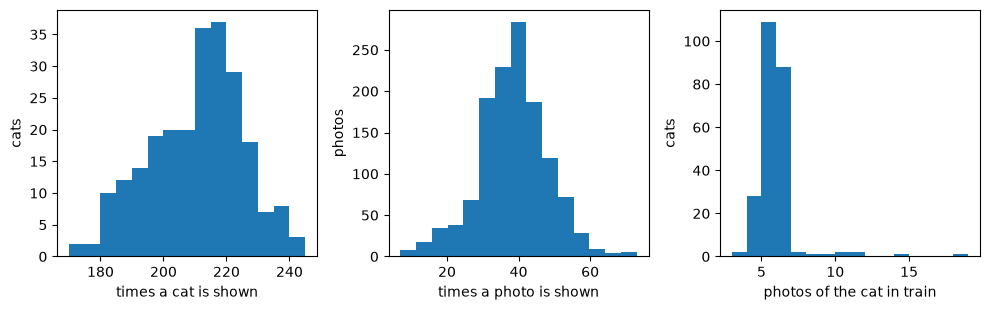

In [7]:
shown = pd.concat(
    [
        train[["a_cat", "a_image", "comparison_type"]].rename(columns={"a_cat": "cat", "a_image": "image"}),
        train[["b_cat", "b_image", "comparison_type"]].rename(columns={"b_cat": "cat", "b_image": "image"}),
    ],
    ignore_index=True,
)
cat_n = shown.groupby("cat").size()
photo_n = shown.groupby("image").size()
photos_per_cat = shown.groupby("cat")["image"].nunique()
within_photos = shown.loc[shown["comparison_type"] == "within_cat"].groupby("cat")["image"].nunique()
missing_from_within = int((within_photos.reindex(photos_per_cat.index).fillna(0) < photos_per_cat).sum())
within = train[train["comparison_type"] == "within_cat"]

print(f"cat appearances: {int(cat_n.min())} to {int(cat_n.max())}, median {cat_n.median():.0f}")
print(f"photo appearances: {int(photo_n.min())} to {int(photo_n.max())}, median {photo_n.median():.0f}")
print(f"photos per cat: {int(photos_per_cat.min())} to {int(photos_per_cat.max())}, median {photos_per_cat.median():.0f}")
print("cats with a photo that never appears in a within-cat pair:", missing_from_within)
print(f"within-cat rows {len(within):,}, unordered pairs {within['unordered_pair_id'].nunique():,}")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].hist(cat_n, bins=15)
axes[0].set_xlabel("times a cat is shown")
axes[0].set_ylabel("cats")
axes[1].hist(photo_n, bins=15)
axes[1].set_xlabel("times a photo is shown")
axes[1].set_ylabel("photos")
axes[2].hist(photos_per_cat, bins=range(int(photos_per_cat.min()), int(photos_per_cat.max()) + 2))
axes[2].set_xlabel("photos of the cat in train")
axes[2].set_ylabel("cats")
fig.tight_layout()
fig.savefig(FIG_DIR / "appearance_counts.png", bbox_inches="tight")
plt.show()

## Choice

A is whichever photo was put on the left. The share choosing A sits a bit above a half for both comparison types, so there is a small tilt toward that slot.

,responses,share
choice,,
A,12921,0.518999
B,11975,0.481001


,responses,share_chose_a
comparison_type,,
within_cat,3003,0.514153
between_cats,21893,0.519664


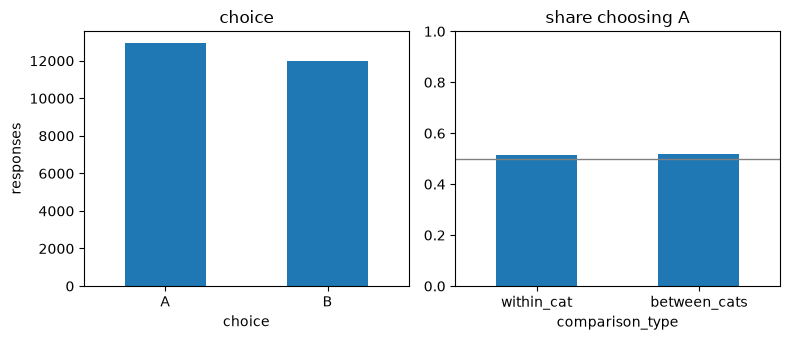

In [8]:
choice_counts = train["choice"].value_counts().rename("responses")
choice_share = train["choice"].value_counts(normalize=True).rename("share")
display(pd.concat([choice_counts, choice_share], axis=1))

by_type = (
    train.groupby("comparison_type")
    .agg(responses=("choice", "size"), share_chose_a=("chose_a", "mean"))
    .reindex(["within_cat", "between_cats"])
)
display(by_type)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
choice_counts.reindex(["A", "B"]).plot.bar(ax=axes[0], rot=0, legend=False)
axes[0].set_title("choice")
axes[0].set_ylabel("responses")

by_type["share_chose_a"].plot.bar(ax=axes[1], rot=0, legend=False)
axes[1].axhline(0.5, color="0.5", lw=1)
axes[1].set_ylim(0, 1)
axes[1].set_title("share choosing A")
fig.tight_layout()
fig.savefig(FIG_DIR / "choice_balance.png", bbox_inches="tight")
plt.show()

## Background

The 508 blank rows are left out of these plots. The red line is the share choosing A on the full training set, blanks included.

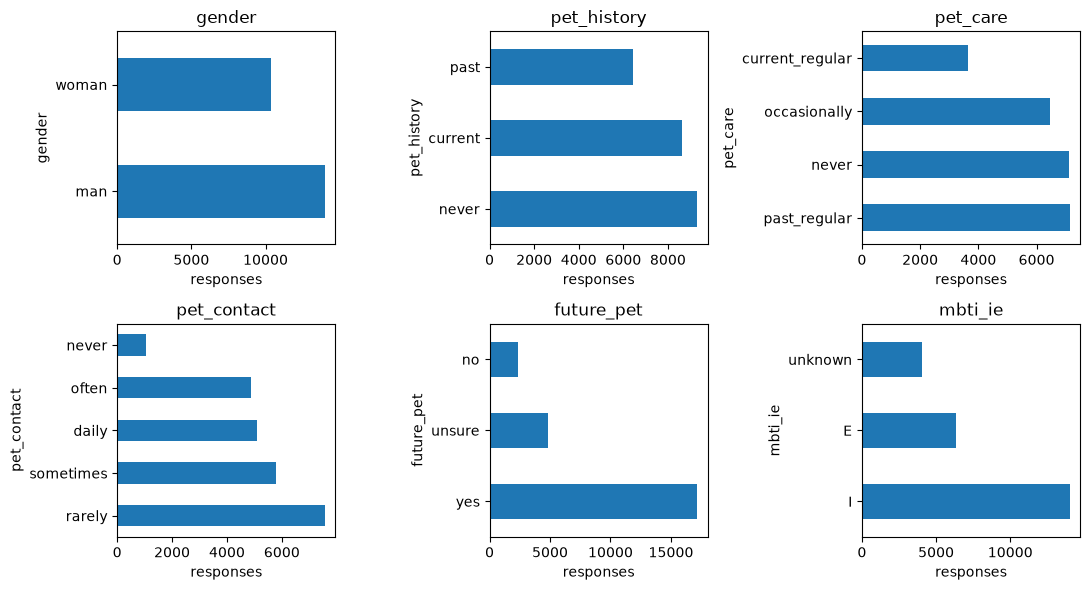

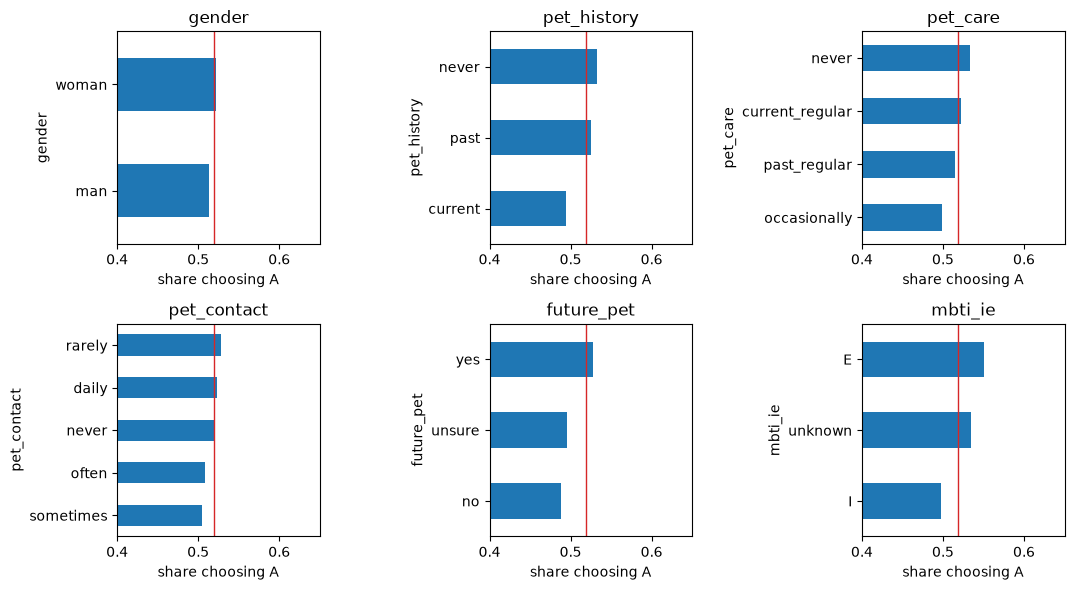

red line = 0.519 on all 24,896 rows


In [9]:
complete = train[train["demo_complete"]].copy()
overall_a = train["chose_a"].mean()

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, col in zip(axes.ravel(), DEMO_COLS):
    complete[col].value_counts().plot.barh(ax=ax)
    ax.set_title(col)
    ax.set_xlabel("responses")
fig.tight_layout()
fig.savefig(FIG_DIR / "background_counts.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, col in zip(axes.ravel(), DEMO_COLS):
    rate = complete.groupby(col)["chose_a"].mean().sort_values()
    rate.plot.barh(ax=ax)
    ax.axvline(overall_a, color="C3", lw=1)
    ax.set_xlim(0.4, 0.65)
    ax.set_title(col)
    ax.set_xlabel("share choosing A")
fig.tight_layout()
fig.savefig(FIG_DIR / "choice_a_by_background.png", bbox_inches="tight")
plt.show()
print(f"red line = {overall_a:.3f} on all {len(train):,} rows")

In [10]:
profile = complete[DEMO_COLS].astype(str).agg(" | ".join, axis=1)
profile_counts = profile.value_counts()
print(f"{profile_counts.size} distinct background profiles among complete rows")
print(f"responses per profile: min {profile_counts.min()}, median {profile_counts.median():.0f}, max {profile_counts.max()}")
profile_counts.head(8).to_frame("responses")

69 distinct background profiles among complete rows
responses per profile: min 92, median 318, max 1600


,responses
man | never | never | rarely | yes | I,1600
woman | never | never | rarely | yes | I,1070
woman | current | current_regular | daily | yes | I,948
man | never | never | never | yes | unknown,646
man | current | occasionally | sometimes | yes | I,645
man | current | occasionally | often | yes | I,629
man | past | past_regular | sometimes | yes | I,627
man | past | past_regular | daily | yes | I,501


## Repeated pairs

Same photo on the left, same photo on the right, answered more than once. Agreement is the share of those pairs where both answers picked the same side.

Matching background fields still isn't one person. The same six answers show up on lots of rows.

In [11]:
multiplicity = train.groupby("ordered_pair_id").size()
display(multiplicity.value_counts().sort_index().rename("ordered pairs").to_frame())

profile_key = train[DEMO_COLS].astype("string").fillna("").agg("|".join, axis=1)
pair_summary = (
    train.assign(_profile=profile_key)
    .groupby("ordered_pair_id")
    .agg(n=("choice", "size"), n_choices=("choice", "nunique"), n_profiles=("_profile", "nunique"))
)
pair_summary = pair_summary[pair_summary["n"] == 2]
print("ordered pairs with two responses:", len(pair_summary))
print("both picked the same side:", round((pair_summary["n_choices"] == 1).mean(), 3))
print("both have the same background profile:", round((pair_summary["n_profiles"] == 1).mean(), 3))

orientations = train.groupby("unordered_pair_id")["ordered_pair_id"].nunique()
print("shown both ways:", int((orientations == 2).sum()))
print("shown one way:", int((orientations == 1).sum()))

,ordered pairs
1,5430
2,9733


ordered pairs with two responses: 9733
both picked the same side: 0.557
both have the same background profile: 0.009
shown both ways: 7114
shown one way: 935


## Agreement and how far apart the cats are

Between-cat pairs answered twice. Both answers match more often when the two cats have different overall win rates. The win rate is the share of between-cat appearances that cat won. Each cat is shown about 200 times, so the pair itself barely moves the rate.

,win_rate_gap,pairs,both_match
0,0.00 to 0.03,1751,0.512
1,0.03 to 0.06,1749,0.533
2,0.06 to 0.10,1751,0.547
3,0.10 to 0.16,1749,0.567
4,0.16 to 0.50,1750,0.647


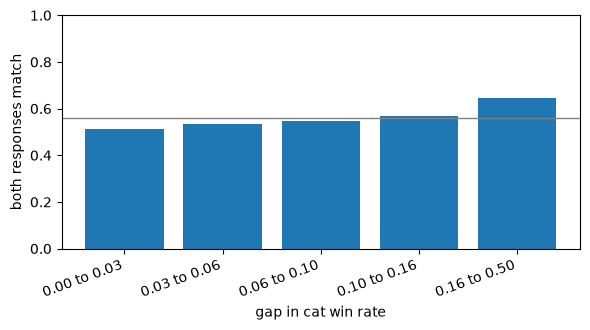

repeated between-cat pairs: both match 0.561, n = 8,750


In [12]:
between = train[train["comparison_type"] == "between_cats"]
wins = pd.concat(
    [
        between[["a_cat", "chose_a"]].rename(columns={"a_cat": "cat"}).assign(won=between["chose_a"].to_numpy()),
        between[["b_cat", "chose_a"]].rename(columns={"b_cat": "cat"}).assign(won=1 - between["chose_a"].to_numpy()),
    ],
    ignore_index=True,
)
cat_win_rate = wins.groupby("cat")["won"].mean()

n_resp = between.groupby("ordered_pair_id").size()
twice = between[between["ordered_pair_id"].isin(n_resp[n_resp == 2].index)]
agree = twice.groupby("ordered_pair_id")["choice"].nunique().eq(1)
meta = twice.groupby("ordered_pair_id").agg(a_cat=("a_cat", "first"), b_cat=("b_cat", "first"))
meta["gap"] = (meta["a_cat"].map(cat_win_rate) - meta["b_cat"].map(cat_win_rate)).abs()
meta["agree"] = agree
meta["gap_bin"] = pd.qcut(meta["gap"], 5)

by_gap = meta.groupby("gap_bin", observed=True)["agree"].agg(pairs="size", both_match="mean").reset_index()
by_gap["win_rate_gap"] = by_gap["gap_bin"].map(lambda iv: f"{max(iv.left, 0):.2f} to {iv.right:.2f}")
display(by_gap[["win_rate_gap", "pairs", "both_match"]].round(3))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(range(len(by_gap)), by_gap["both_match"])
ax.set_xticks(range(len(by_gap)), by_gap["win_rate_gap"], rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("both responses match")
ax.set_xlabel("gap in cat win rate")
ax.axhline(meta["agree"].mean(), color="0.5", lw=1)
fig.tight_layout()
fig.savefig(FIG_DIR / "agreement_by_win_gap.png", bbox_inches="tight")
plt.show()
print(f"repeated between-cat pairs: both match {meta['agree'].mean():.3f}, n = {len(meta):,}")

## What changed

BOM stripped on read. The 508 all-blank background rows are still in the file, with those fields missing and `demo_complete` false. Ids, labels, paths, and image files checked out, so the cleaned table has the same 24,896 rows. Extra images on disk that train never uses are still in `cat-arena/photos`.